## **TASK 1: PlantVillage Dataset Exploration & Preprocessing**


In [1]:
!pip install kagglehub

In [2]:
import os
import kagglehub
path = kagglehub.dataset_download("mohitsingh1804/plantvillage")
print(path)

C:\Users\monika\.cache\kagglehub\datasets\mohitsingh1804\plantvillage\versions\1


In [3]:
# Step 3b: Check what's inside the PlantVillage folder
inner_path = os.path.join(path, "PlantVillage")
print(os.listdir(inner_path)[:10])

['train', 'val']


In [4]:
# Step 3c: Check inside train folder
train_path = os.path.join(inner_path, "train")
classes = os.listdir(train_path)
print(f"Total classes: {len(classes)}")
print(classes[:5])

Total classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [5]:
# Set path to training data for exploration
path = train_path

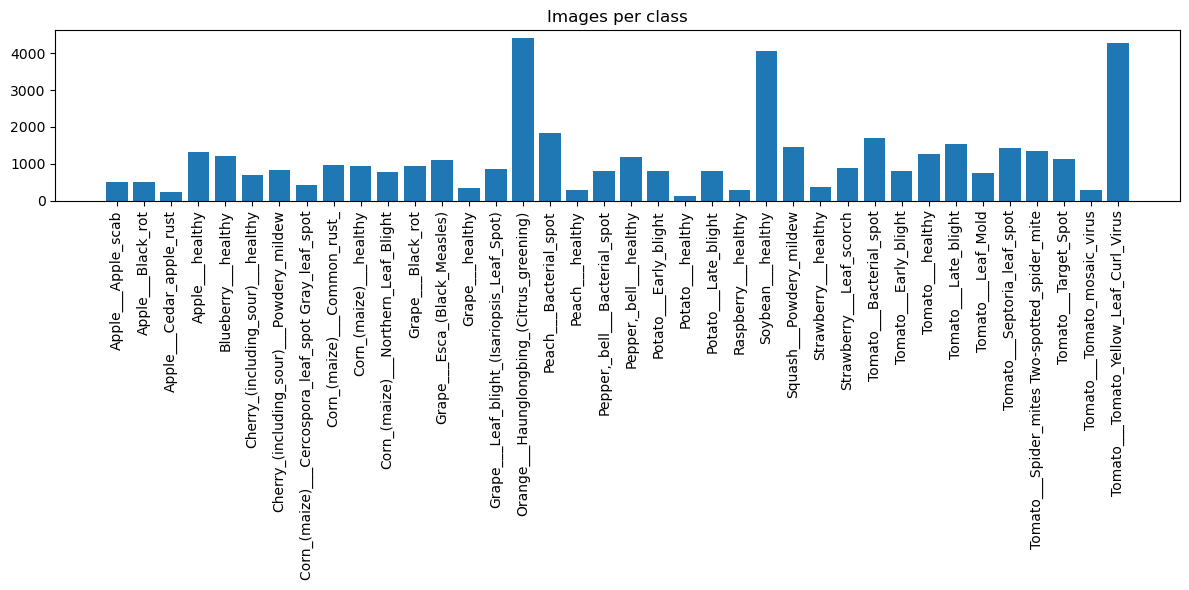

In [6]:
# Step 4: Visualize number of images per class (class distribution)
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(os.path.join(path, c))) for c in classes}
plt.figure(figsize=(12,6))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=90)
plt.title("Images per class")
plt.tight_layout()
plt.show()

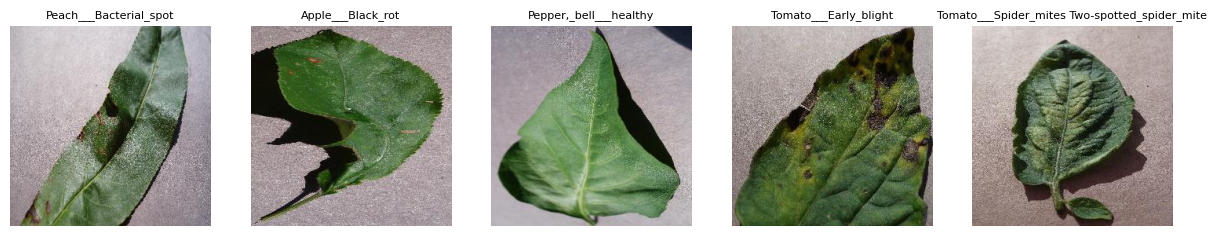

In [7]:
# Step 5: Preview random sample images from different classes
from PIL import Image
import random

fig, axes = plt.subplots(1, 5, figsize=(15,3))
sample_classes = random.sample(classes, 5)
for ax, cls in zip(axes, sample_classes):
    img_file = os.listdir(os.path.join(path, cls))[0]
    img = Image.open(os.path.join(path, cls, img_file))
    ax.imshow(img)
    ax.set_title(cls, fontsize=8)
    ax.axis('off')
plt.show()

## **TASK 2: Machine Learning Model — Training & Evaluation**

### Model 1: SVM (Support Vector Machine) — baseline model

In [31]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [33]:
def load(folder, n, size=(32, 32)):
    X, y = [], []
    for c in sorted(os.listdir(folder)):
        for f in os.listdir(os.path.join(folder, c))[:n]:
            img = Image.open(os.path.join(folder, c, f)).convert("RGB").resize(size)
            X.append(np.array(img).flatten() / 255.0)
            y.append(c)
    return np.array(X), np.array(y)

X_train, y_train = load(train_path, 100)
X_test,  y_test  = load(os.path.join(inner_path, "val"), 30)
print(X_train.shape, X_test.shape)

(3800, 3072) (1140, 3072)


In [34]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s  = sc.transform(X_test)

svm = SVC(kernel="rbf").fit(X_train_s, y_train)


def score(y_true, p):
    return [accuracy_score(y_true, p),
            precision_score(y_true, p, average="weighted", zero_division=0),
            recall_score(y_true, p, average="weighted"),
            f1_score(y_true, p, average="weighted")]

results = pd.DataFrame([score(y_test, svm.predict(X_test_s))],
                       columns=["Accuracy", "Precision", "Recall", "F1"],
                       index=["SVM"])
print(results.round(3))

     Accuracy  Precision  Recall     F1
SVM     0.626      0.627   0.626  0.622


### Model 2: CNN (Convolutional Neural Network) — 3 convolutional layers

In [35]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [37]:
img_size = (64, 64)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path, image_size=img_size, batch_size=batch_size)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(inner_path, "val"), image_size=img_size, batch_size=batch_size)

class_names = train_ds.class_names

normalize = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalize(x), y))
val_ds = val_ds.map(lambda x, y: (normalize(x), y))

Found 43444 files belonging to 38 classes.
Found 10861 files belonging to 38 classes.


In [38]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)                   │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │         589,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 38)                  │           2,470 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 648,678 (2.47 MB)

 Trainable params: 648,678 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 100s 72ms/step - accuracy: 0.6121 - loss: 1.3707 - val_accuracy: 0.7571 - val_loss: 0.7680
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 98s 72ms/step - accuracy: 0.8221 - loss: 0.5685 - val_accuracy: 0.8247 - val_loss: 0.5585
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 98s 72ms/step - accuracy: 0.8746 - loss: 0.3962 - val_accuracy: 0.8699 - val_loss: 0.4218
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 99s 73ms/step - accuracy: 0.9009 - loss: 0.3059 - val_accuracy: 0.8772 - val_loss: 0.3995
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 394s 290ms/step - accuracy: 0.9198 - loss: 0.2381 - val_accuracy: 0.8740 - val_loss: 0.4209
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 78s 57ms/step - accuracy: 0.9371 - loss: 0.1870 - val_accuracy: 0.8937 - val_loss: 0.3511
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 76s 56ms/step - accuracy: 0.9482 - loss: 0.1553 - val_accuracy: 0.9060 - val_loss: 0.3442
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 82s 56ms/step - accuracy: 0.956

### Results

In [41]:
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

results.loc["CNN"] = [
    accuracy_score(y_true, y_pred),
    precision_score(y_true, y_pred, average="weighted", zero_division=0),
    recall_score(y_true, y_pred, average="weighted"),
    f1_score(y_true, y_pred, average="weighted")
]
print(results.round(3))

     Accuracy  Precision  Recall     F1
SVM     0.626      0.627   0.626  0.622
CNN     0.887      0.897   0.887  0.888


## **Conclusion**
* Two models were trained and evaluated on the PlantVillage leaf dataset: SVM (with 
an RBF kernel) and a Convolutional Neural Network (CNN).
* The CNN achieved 88.7% 
accuracy, significantly outperforming SVM's 62.6%. This is because the CNN 
processes images as 2D grids and learns spatial features (edges, shapes, textures, 
disease spot patterns) directly through convolutional filters, while SVM relies 
on flattened pixel values that lose this spatial structure.
* The CNN is clearly 
the best-performing and most suitable model for this image classification task.